In [1]:
# Descubrimiento robusto de la raiz del proyecto (no usar ../ relativo)
import pathlib as _pl, os as _os, sys as _sys
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
_os.chdir(_ROOT)
if str(_ROOT) not in _sys.path:
    _sys.path.insert(0, str(_ROOT))
if str(_ROOT / "src") not in _sys.path:
    _sys.path.insert(0, str(_ROOT / "src"))
print("cwd:", _os.getcwd())

# --- MLflow live (mlflow-live-notebooks): env BEFORE any TF/Keras import ---
_os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
_os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
_os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
_os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
_os.environ.setdefault("OMP_NUM_THREADS", "1")
from ds02_rul.mlflow_live import log_live_run, persist_timings, setup_mlflow
setup_mlflow()
print("mlflow live: store=mlruns-live experiment=ds02-clase (fuente=live_notebook)")


cwd: C:\Users\mikel\Desktop\Pruebas\nasa
mlflow live: store=mlruns-live experiment=ds02-clase (fuente=live_notebook)


## Alcance y reproducibilidad

Este cuaderno describe el EDA que justifica el preprocesado. No entrena modelos: los seis PNG de `resultados/eda_*.png` salen de aquí.

- `train.parquet` y `test.parquet` se generan en `src/clase/dataset_clase.py`; el test (11/14/15) se lee una vez.
- La imputación usa solo los fit-units (2/5/10/18/20); la mediana de train no toca test.
- `fase_vuelo` sale de `alt` y `Mach`, nunca de sensores ni de RUL.
- El Ridge de este cuaderno es físico: 14 modelos por sensor que quitan régimen. No es el Ridge de fila de 02 ni el meta de 05.


# 01 — EDA DS02 (SAA 3/4/5)

Dataset: N-CMAPSS DS02 con `STRIDE=100`; 65.173 lecturas y 9 motores. El parquet trae 23 columnas físicas: 22 entran al contrato del modelo y `split_origen` queda como trazabilidad. Train = dev (uds 2/5/10/18/20/16, 52.635); test = uds 11/14/15 (12.538, se evalúa una vez). Objetivo: RUL, regresión supervisada.

Los nulos son MAR (~1,8 %) y están solo en T30, en crucero alto (alt > 27k y Mach > 0,68). Se imputan con `ffill` causal por unidad y mediana de train para el primer hueco. `fase_vuelo` se deriva solo de alt/Mach (18k / 26k + 0,65).


## Por qué esto es IA débil y supervisada (SAA 1/2)

- **IA débil**: solo predice RUL de DS02 a partir de telemetría aprendida. Una **IA fuerte** (AGI: fijar precios, atender llamadas, razonar en cualquier dominio) no existe aquí: el sistema no transfiere nada fuera de DS02. Ventaja de lo débil: barata, rápida, auditable.
- **Supervisado, regresión**: cada fila trae su RUL real (etiqueta continua = ciclos restantes). Se diferencia del no supervisado en que hay etiqueta y métrica contra verdad (RMSE/MAE/R²).


## Glosario rápido (para seguir el notebook sin perderte)

| Palabra | Que significa aquí |
|---|---|
| RUL | Ciclos que le quedan al motor. Es lo que predecimos (número, no categoria: regresion). |
| MAR | El nulo tiene causa conocida (aquí: la sonda T30 se pierde en crucero alto). Se puede modelar. |
| MCAR | El nulo cae al azar, sin causa. Mas facil de ignorar, menos realista. |
| ffill causal | Rellenar cada hueco con el ultimo valor *anterior* del mismo motor. Nunca mira al futuro: sin fuga. |
| Fuga (leakage) | Usar en entreno informacion que en produccion no tendrias (p. ej. medianas del test, o filas futuras). Invalida el experimento. |
| OneHot | Convertir `fase_vuelo` en 3 columnas 0/1 (Ascenso/Crucero/Descenso) para que el modelo la pueda usar. |
| Ridge | Regresión lineal con castigo alpha. Aquí lo usamos 3 veces con rol distinto: en 01 limpia sensores (física), en 02 predice RUL por fila (baseline), en 04/05 mezcla dos predicciones del bundle C. Fijate en el sufijo. |
| Split por motor | Entrenar con unos motores y probar con otros distintos (11/14/15). Si mezclas filas del mismo motor en ambos lados, el modelo "recuerda" en vez de generalizar. |

> Como leer este notebook: cada figura trae su QUÉ VEO (lo literal) y su CONCLUSIÓN (qué decisión de modelado sale de ahí). Si solo tienes 5 minutos, lee los títulos + conclusiones.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

train = pd.read_parquet('data/processed/train.parquet')
test = pd.read_parquet('data/processed/test.parquet')
audit = json.load(open('data/processed/auditoria_nulos.json'))
SENSORES = ['T24','T30','T48','T50','P15','P2','P21','P24','Ps30','P40','P50','Nf','Nc','Wf']
print('train', train.shape, '| test', test.shape)
print('mecanismo', audit.get('mecanismo'), '| sensor', audit.get('sensor'), '| cond', audit.get('condicion')); print('tasa_global_T30', round(audit.get('tasa_global_T30', audit.get('tasa_real',0)), 4), '| elegibles', audit.get('filas_elegibles'), '| nulos', audit.get('nulos_inyectados'))
print('fase train', train['fase_vuelo'].value_counts().to_dict())
print('fase test', test['fase_vuelo'].value_counts().to_dict())
print('RUL train media', round(train['RUL'].mean(), 2), '| test media', round(test['RUL'].mean(), 2))


train (52635, 23) | test (12538, 23)
mecanismo MAR-altitud | sensor T30 | cond alt>27000 & Mach>0.68
tasa_global_T30 0.0182 | elegibles 12499 | nulos 1185
fase train {'Descenso': 23318, 'Crucero': 15813, 'Ascenso': 13504}
fase test {'Descenso': 5681, 'Ascenso': 5091, 'Crucero': 1766}
RUL train media 37.33 | test media 31.3


## Tabla de campos + calidad

| campo | qué significa | tipo | %nulos antes (MAR T30) | %nulos después | descarte |
|---|---|---|---|---|---|
| unit | motor (id DS02) | numérica (grupo, no predictor) | 0% | 0% — nunca se inyecta | grupo |
| cycle | ciclo de vuelo (despegue-aterrizaje) | numérica (tiempo) | 0% | 0% | se mantiene |
| alt | altitud (ft) | numérica (régimen) | 0% | 0% | se mantiene |
| Mach | número Mach | numérica (régimen) | 0% | 0% | se mantiene |
| TRA | ángulo de palanca de potencia (throttle resolver angle) | numérica (régimen) | 0% | 0% | se mantiene |
| T2 | temp. entrada fan (°R) | numérica (régimen) | 0% | 0% | se mantiene |
| T24 | temp. salida LPC (°R) | numérica | 0% | 0% | se mantiene |
| T30 | temp. salida HPC (°R) — sonda con dropout | numérica | ~1.8% MAR (crucero alto) | 0% tras ffill+mediana | se mantiene |
| T48 | temp. salida HPT (°R) | numérica | 0% | 0% | se mantiene |
| T50 | temp. salida LPT (°R) | numérica | 0% | 0% | se mantiene |
| P15 | presión sangrado (psia) | numérica | 0% | 0% | se mantiene |
| P2 | presión entrada fan (psia) | numérica | 0% | 0% | se mantiene |
| P21 | presión salida LPC (psia) | numérica | 0% | 0% | se mantiene |
| P24 | presión salida HPC (psia) | numérica | 0% | 0% | se mantiene |
| Ps30 | presión estática HPC (psia) | numérica | 0% | 0% | se mantiene |
| P40 | presión total HPT (psia) | numérica | 0% | 0% | se mantiene |
| P50 | presión total LPT (psia) | numérica | 0% | 0% | se mantiene |
| Nf | rpm del fan | numérica | 0% | 0% | se mantiene |
| Nc | rpm del núcleo | numérica | 0% | 0% | se mantiene |
| Wf | caudal combustible (pps) | numérica | 0% | 0% | se mantiene |
| RUL | **objetivo**: ciclos restantes | numérica | 0% | 0% — nunca se inyecta | objetivo |
| split_origen | origen del split (train/test) | categórica (trazabilidad) | 0% | 0% | trazabilidad |
| fase_vuelo | Ascenso/Crucero/Descenso (nueva, derivada de alt/Mach) | categórica | 0% (derivada) | 0% | se mantiene |

**Descartes:** ninguna columna se elimina; la columna `descarte` dice su destino: `unit`→grupo (no entra como predictor numérico, se usa como grupo en GroupKFold), `RUL`→objetivo, `split_origen`→trazabilidad, el resto se mantiene. Duplicados e imposibles se chequean abajo.


**Qué vemos (tabla de campos, nulos antes/después).** Solo T30 trae nulos (~1,8 % MAR en crucero alto); el resto 0 % antes y 0 % después. después de ffill + mediana todo queda en 0 %: la imputacion no deja huecos, y el 1,8 % inicial es el tamano del problema resuelto, no un defecto del dataset. `unit` y `RUL` nunca se imputan: son grupo y objetivo.


In [3]:
print('duplicados train:', int(train.duplicated().sum()))
print('RUL<0:', int((train['RUL'] < 0).sum()), '| cycle<=0:', int((train['cycle'] <= 0).sum()))
print('Mach fuera [0.2,0.9]:', int(((train['Mach'] < 0.2) | (train['Mach'] > 0.9)).sum()))
# % nulos auditados por sensor (antes de imputar)
nulos = pd.Series(audit['nulos_por_col']).sort_values(ascending=False)
print(nulos.to_string())
print('filas con algún nulo:', audit['filas_con_algun_nulo'])
# Patrón: correlación de co-ocurrencia de nulos entre sensores (MCAR → ~0)
print('RUL media por fase (train):')
print(train.groupby('fase_vuelo')['RUL'].mean().round(2).to_string())


duplicados train: 0
RUL<0: 0 | cycle<=0: 0
Mach fuera [0.2,0.9]: 0
T30    1185
filas con algún nulo: 1185
RUL media por fase (train):
fase_vuelo
Ascenso     37.05
Crucero     37.89
Descenso    37.11


**Qué vemos (RUL media 37.33 train frente a 31.3 test; por fase 37.05 / 37.89 / 37.11).** La media de test es casi 6 ciclos menor porque el motor 11 pesa mas de la mitad (6.635 de 12.538 filas, RUL media 29.0): manda el 11. La media por fase apenas se mueve (Ascenso 37.05, Crucero 37.89, Descenso 37.11), así que la fase sola no predice: hay que medir degradacion, no calendario.


## Fig.1 — Barras: reparto de fase_vuelo (train)
*Cómo leer: Lee primero la altura de Crucero: ahí vive el MAR de T30.*


QUÉ VEO: tres fases presentes (~26/30/44%), sin categoría vacía.
CONCLUSIÓN: la categórica sirve para OneHot (PIA 3); el Crucero concentra RUL alta.


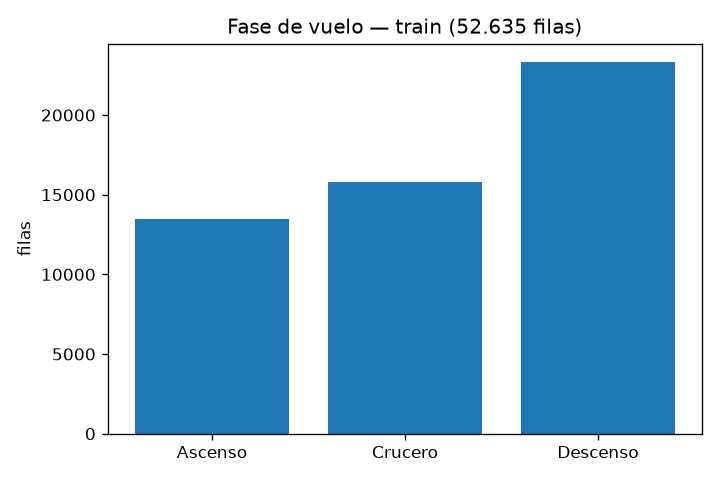

In [4]:
ct = pd.crosstab(train['fase_vuelo'], 'n')
fig, ax = plt.subplots(figsize=(6, 4))
orden = ['Ascenso', 'Crucero', 'Descenso']
vals = [int((train['fase_vuelo'] == f).sum()) for f in orden]
ax.bar(orden, vals)
ax.set_title('Fase de vuelo — train (52.635 filas)')
ax.set_ylabel('filas')
fig.tight_layout(); fig.savefig('resultados/eda_barras_fase.png', dpi=120); plt.close(fig)
print('QUÉ VEO: tres fases presentes (~26/30/44%), sin categoría vacía.')
print('CONCLUSIÓN: la categórica sirve para OneHot (PIA 3); el Crucero concentra RUL alta.')
from IPython.display import Image, display
display(Image('resultados/eda_barras_fase.png'))


**Qué concluyo (Fig. 1).** El descenso domina el train (23.318 filas, 44,3 %), seguido de crucero (15.813, 30,0 %) y ascenso (13.504, 25,7 %). El modelo ve mas descenso que ascenso: cualquier lectura de altitud o temperatura hay que hacerla por fase, no en agregado.


## Fig.2 — Histograma RUL + Fig.3 — Boxplot sensor (T48) por fase
*Cómo leer: Fíjate en la cola de la derecha (motores jóvenes) y en que T48 separa fases: el régimen manda.*


QUÉ VEO: RUL asimétrica con cola larga (motores jóvenes) y masa en RUL baja.
CONCLUSIÓN: regresión con RMSE+MAE+R²; MAE protege de la cola, RMSE penaliza fallos gordos.
QUÉ VEO: T48 separada por fase (régimen manda en el sensor crudo).
CONCLUSIÓN: sin desacoplar régimen, el modelo aprendería pilotaje, no degradación (como ADR-002).


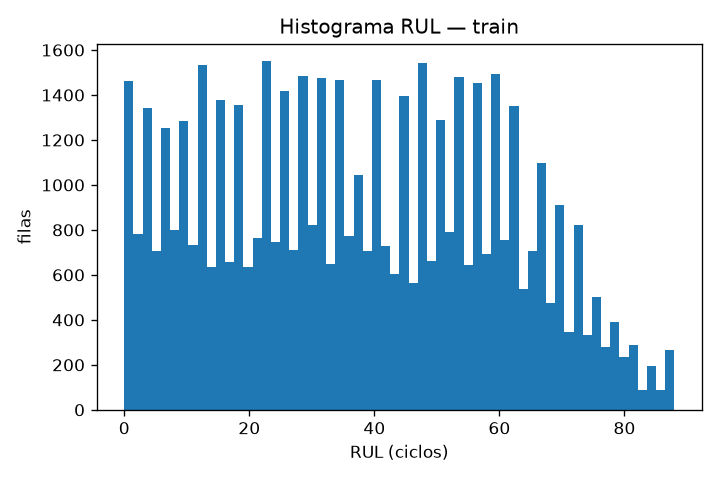

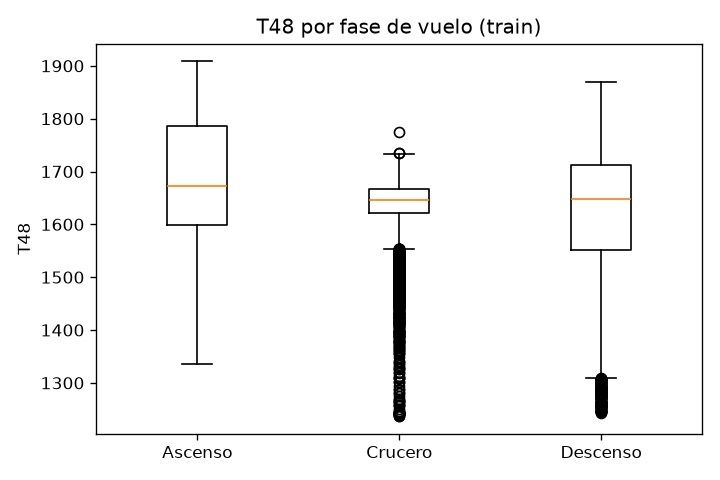

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(train['RUL'].to_numpy(), bins=60)
ax.set_title('Histograma RUL — train')
ax.set_xlabel('RUL (ciclos)'); ax.set_ylabel('filas')
fig.tight_layout(); fig.savefig('resultados/eda_hist_rul.png', dpi=120); plt.close(fig)
print('QUÉ VEO: RUL asimétrica con cola larga (motores jóvenes) y masa en RUL baja.')
print('CONCLUSIÓN: regresión con RMSE+MAE+R²; MAE protege de la cola, RMSE penaliza fallos gordos.')
fig, ax = plt.subplots(figsize=(6, 4))
datos = [train.loc[train['fase_vuelo'] == f, 'T48'].to_numpy() for f in ['Ascenso', 'Crucero', 'Descenso']]
ax.boxplot(datos, tick_labels=['Ascenso', 'Crucero', 'Descenso'])
ax.set_title('T48 por fase de vuelo (train)')
ax.set_ylabel('T48')
fig.tight_layout(); fig.savefig('resultados/eda_box_t48_fase.png', dpi=120); plt.close(fig)
print('QUÉ VEO: T48 separada por fase (régimen manda en el sensor crudo).')
print('CONCLUSIÓN: sin desacoplar régimen, el modelo aprendería pilotaje, no degradación (como ADR-002).')
from IPython.display import Image, display
display(Image('resultados/eda_hist_rul.png'))
display(Image('resultados/eda_box_t48_fase.png'))


**Qué concluyo (Fig. 2 y 3).** La RUL del train va de 0 a 88 ciclos, con media 37,33 y mediana 36: distribucion asimetrica y sin cola de motores jovenes por encima de 100 (0,0 %). El 26,5 % de las filas esta por debajo de RUL 20, que es donde se juega la alarma. La T48 cruda separa fases por su mediana (Ascenso 1.673,5 · Crucero 1.646,5 · Descenso 1.647,7) y sobre todo por su dispersion (IQR: Ascenso 1.599-1.787, Descenso 1.551-1.712): sin desacoplar regimen, el modelo aprenderia pilotaje.


## Fig.4 — Dispersión alt vs Mach coloreada por fase
*Cómo leer: Cada símbolo es una fase; si se mezclaran, los umbrales estarían mal.*


QUÉ VEO: la fase corta el plano alt-Mach en bandas coherentes, sin solape raro.
CONCLUSIÓN: umbrales 18k/26k+0.65 válidos en DS02; la fase resume régimen sin usar sensores.


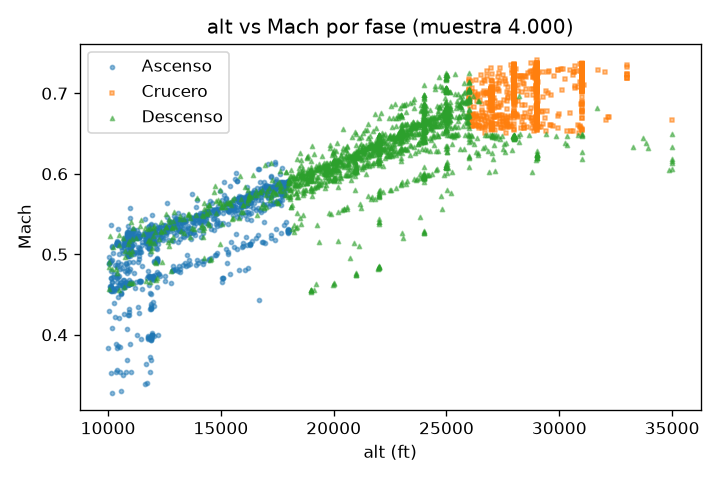

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
muestra = train.sample(4000, random_state=0)
for f, m in [('Ascenso', 'o'), ('Crucero', 's'), ('Descenso', '^')]:
    s = muestra[muestra['fase_vuelo'] == f]
    ax.scatter(s['alt'], s['Mach'], s=6, marker=m, label=f, alpha=0.5)
ax.set_title('alt vs Mach por fase (muestra 4.000)')
ax.set_xlabel('alt (ft)'); ax.set_ylabel('Mach'); ax.legend()
fig.tight_layout(); fig.savefig('resultados/eda_scatter_alt_mach.png', dpi=120); plt.close(fig)
print('QUÉ VEO: la fase corta el plano alt-Mach en bandas coherentes, sin solape raro.')
print('CONCLUSIÓN: umbrales 18k/26k+0.65 válidos en DS02; la fase resume régimen sin usar sensores.')
from IPython.display import Image, display
display(Image('resultados/eda_scatter_alt_mach.png'))


**Qué concluyo (Fig. 4).** Ascenso, crucero y descenso ocupan nubes separadas en altitud (10.001-35.029 ft) y Mach (0,327-0,742); el solape es pequeno. Eso justifica partir el análisis por fase: una media global mezclaria regimenes distintos.


## Fig.5 — Heatmap correlación (régimen + 4 sensores + RUL)
*Cómo leer: Mira la última fila/columna (RUL): correlaciones débiles = una fila no basta.*


       alt  Mach   T48   P15    Nf    Wf   RUL
alt   1.00  0.92 -0.08 -0.96  0.29 -0.58  0.01
Mach  0.92  1.00 -0.01 -0.84  0.33 -0.48  0.02
T48  -0.08 -0.01  1.00  0.32  0.93  0.84 -0.07
P15  -0.96 -0.84  0.32  1.00 -0.04  0.77 -0.01
Nf    0.29  0.33  0.93 -0.04  1.00  0.59  0.01
Wf   -0.58 -0.48  0.84  0.77  0.59  1.00 -0.02
RUL   0.01  0.02 -0.07 -0.01  0.01 -0.02  1.00
QUÉ VEO: sensores correlados entre sí; RUL correlaciona débil con variables instantáneas.
CONCLUSIÓN: RUL no sale de una fila (hace falta historia/tendencia); justifica modelos no lineales + validación por motor.


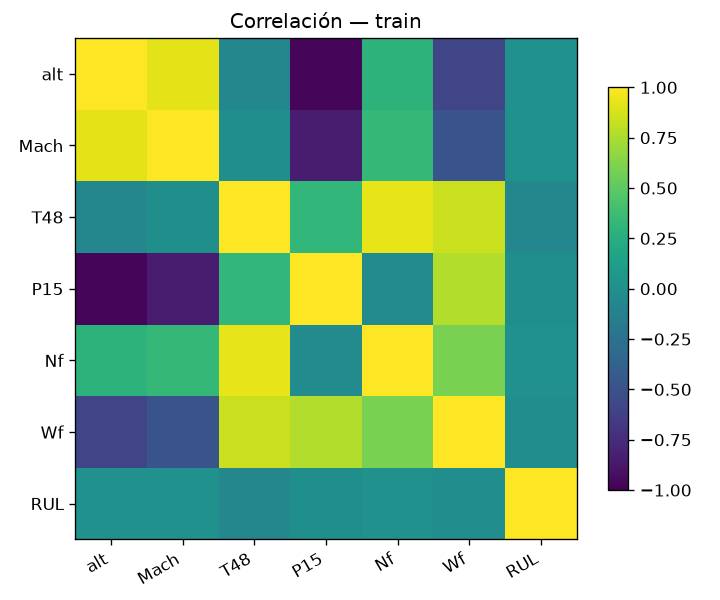

In [7]:
cols = ['alt', 'Mach', 'T48', 'P15', 'Nf', 'Wf', 'RUL']
C = train[cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(C.to_numpy(), vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=30, ha='right')
ax.set_yticks(range(len(cols)), cols)
ax.set_title('Correlación — train')
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout(); fig.savefig('resultados/eda_heatmap_corr.png', dpi=120); plt.close(fig)
print(C.round(2).to_string())
print('QUÉ VEO: sensores correlados entre sí; RUL correlaciona débil con variables instantáneas.')
print('CONCLUSIÓN: RUL no sale de una fila (hace falta historia/tendencia); justifica modelos no lineales + validación por motor.')
from IPython.display import Image, display
display(Image('resultados/eda_heatmap_corr.png'))


**Qué concluyo (Fig. 5).** Ninguna variable instantanea explica la RUL: |r| <= 0,07 en las seis (alt 0,01 · Mach 0,02 · T48 -0,07 · P15 -0,01 · Nf 0,01 · Wf -0,02). Lo que si aparece es colinealidad fuerte entre entradas (alt-P15 -0,96 · T48-Nf 0,93 · alt-Mach 0,92 · Mach-P15 -0,84), así que una fila no basta y el modelo necesita historia/tendencia; de ahi ventanas, BiLSTM y validacion por motor.


## Cierre EDA → modelado

- Nulos MAR ~1.8% en T30 auditados (`auditoria_nulos.json`), imputación causal sin fuga (medianas solo train, test con las de train).
- `fase_vuelo` útil: 3 niveles no vacíos, RUL media distinta por fase, permite `OneHot` exigido en PIA 3.
- Split por motor (train dev / test 11-14-15); test se toca 1 vez en Fase 2 con el modelo elegido.
- Figuras para README §5: `eda_barras_fase.png` + `eda_scatter_alt_mach.png` (las demás quedan en `resultados/`).

> TIP (fuga): las medianas de imputacion se calculan SOLO con train y se aplican a test. Si las calcularas con todo el dataset, el test "contaminaria" el entreno y el RMSE mentiria a la baja. Lo mismo con `fase_vuelo`: solo usa alt/Mach (régimen), nunca sensores ni RUL.

**Procedencia de los datos:** `data/raw/DS02*.hdf5` (original NASA, intacto) → `src/clase/dataset_clase.py` (inyecta MAR + imputa + fase) → `data/processed/train|test.parquet` (lo que carga este notebook). La auditoría vive en `data/processed/auditoria_nulos.json`.


## Las dos ligas (léeme antes de seguir)

Piensa en dos juegos distintos con los mismos motores:

| Liga | Qué es una fila | Train | Test | Modelos |
|---|---|---|---|---|
| **Fila** | 1 ciclo de vuelo | 52.635 filas | 12.538 filas | 02 (clásicos) y 03 (MLP) |
| **Ventana** | 50 lecturas que terminan en un ciclo | 17.450 ventanas | 6.196 ventanas | 04 (LGBM) y 05 (híbrido C) |

**Regla de oro:** no se comparan entre ligas. Cada liga elige a su campeón. Al final (05) los ponemos lado a lado, sin mezclar.


**Cómo leer (antes de seguir: definiciones en una linea).** RMSE: raiz del error cuadratico medio, en ciclos; 4.338 en C significa fallo tipico de unos 4 ciclos. MAE: error absoluto medio, cuanto se equivoca de media (3.227 en C). R2: parte de la varianza de la RUL explicada; 0.9461 en C es explicar casi todo. NASA Score: coste asimetrico sobre las 6.196 ventanas de test, pasarse de RUL cuesta mas que quedarse corto (2336.2 en C). Macro: cada motor pesa 1/3 aunque tenga pocas ventanas; 5.0153 frente a 4.338 global. Grano: fila = 1 ciclo (02/03), ventana = 50 lecturas (04/05); nunca se comparan mezclas.


In [8]:
# Las dos ligas, calculadas (no copiadas a mano)
print(f"train filas: {len(train)} | test filas: {len(test)}")
print("Liga fila: 1 fila = 1 ciclo. Modelos 02/03.")
print("Liga ventana: 1 ventana = 50 lecturas. Modelos 04/05.")
print("Unidades fit [2,5,10,18,20] | holdout 16 | test [11,14,15]")


train filas: 52635 | test filas: 12538
Liga fila: 1 fila = 1 ciclo. Modelos 02/03.
Liga ventana: 1 ventana = 50 lecturas. Modelos 04/05.
Unidades fit [2,5,10,18,20] | holdout 16 | test [11,14,15]


## Nulos MAR, en cristiano

El sensor T30 se apaga a ratos **solo cuando el avión va alto y rápido** (crucero). No es al azar: es MAR (falta con patrón físico).

Ecuación: si `alt > 27000 y Mach > 0.68`, cada fila tiene 10% de perder T30 (seed 7). Resultado real: ~1.8% de T30 en todo el dataset.


In [9]:
# Nulos MAR recalculados en vivo (sin fiarse del CSV)
from src.clase.dataset_clase import elegibles_mar
import json, pandas as pd
dfc = pd.read_parquet('data/processed/train_con_nulos.parquet')
nulos = int(dfc['T30'].isna().sum())
elig = int(elegibles_mar(dfc).sum())
print(f"filas elegibles crucero: {elig} | nulos T30: {nulos} | tasa global {nulos/len(dfc):.2%}")
aud = json.load(open('data/processed/auditoria_nulos.json', encoding='utf-8'))
print("auditoría:", {k: aud[k] for k in list(aud)[:5]})
assert dfc['RUL'].isna().sum() == 0, "RUL nunca tiene nulos"
print("OK: RUL intacto, nulos solo en T30")


filas elegibles crucero: 11293 | nulos T30: 1056 | tasa global 2.01%
auditoría: {'mecanismo': 'MAR-altitud', 'sensor': 'T30', 'condicion': 'alt>27000 & Mach>0.68', 'tasa_elegible_pedida': 0.1, 'seed': 7}
OK: RUL intacto, nulos solo en T30


## Imputación: lo que haría un ingeniero en pista

Hueco en T30 → **copia el último valor conocido de ese motor** (ffill causal, ordenado por ciclo). Si el hueco está al principio y no hay pasado → **mediana de train** (solo fit-units, sin mirar test).

Así no hay fuga: el test se rellena con números del train.


In [10]:
# Imputación en vivo (misma función que usan 02-05)
from ds02_rul.data import imputar_ffill, SENSOR_COLS
import pandas as pd
FIT = [2.0, 5.0, 10.0, 18.0, 20.0]
df_tr = pd.read_parquet('data/processed/train_con_nulos.parquet')
med = df_tr[df_tr['unit'].isin(FIT)][SENSOR_COLS].median(numeric_only=True)
imp, _ = imputar_ffill(df_tr, med, SENSOR_COLS)
print("nulos tras imputar:", int(imp[SENSOR_COLS].isna().sum().sum()))
assert int(imp[SENSOR_COLS].isna().sum().sum()) == 0
print("OK: 0 nulos, sin fuga (medianas solo fit-units)")


nulos tras imputar: 0
OK: 0 nulos, sin fuga (medianas solo fit-units)


## Residualización: quitar el efecto del pilotaje

Idea física: **¿el motor se calienta porque se rompe o porque el avión sube a tope?** Restamos el calor normal del régimen (Ridge sobre alt/Mach/TRA/T2 en polinomio grado 2) y nos quedamos con el residuo = degradación.

Sin esto, el modelo aprendería pilotaje, no salud.

**Ojo, no confundir:** Esto NO es el Ridge clasico de 02 ni el ridge_meta de 05. Este limpia sensores antes de modelar; no predice RUL. `fase_vuelo` es una etiqueta discreta (Ascenso/Crucero/Descenso desde alt/Mach) para OneHot en fila; el residualizer es una resta continua por sensor para ventana. Coexisten por eso.


In [11]:
# Residualización en vivo (objetos que reutilizan 04/05)
from ds02_rul.features import fit_preprocessing
import numpy as np
W_fit = imp[imp['unit'].isin(FIT)][['alt','Mach','TRA','T2']].to_numpy(dtype=float)
Xs_fit = imp[imp['unit'].isin(FIT)][SENSOR_COLS].to_numpy(dtype=float)
prep = fit_preprocessing(W_fit, Xs_fit)
print("ridges:", len(prep['residualizer'].ridges), "| scaler entrada:", prep['scaler'].n_features_in_)
print("OK: prep ajustado solo en fit-units")


ridges: 14 | scaler entrada: 18
OK: prep ajustado solo en fit-units


## Fig.6 — T48 residualizado por fase (prueba de que el preprocesado quita regimen)
*Cómo leer: compara con Fig.3. Si el recuadro se achica, el Ridge fisico hizo su trabajo.*



QUÉ VEO: las cajas se solapan mucho mas que en Fig.3.
CONCLUSIÓN: el Ridge fisico quita regimen; el residuo ya no aprende pilotaje.


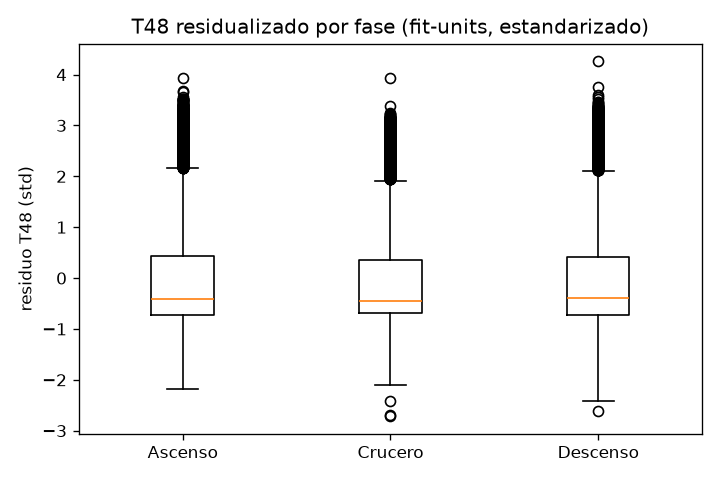

In [12]:
# Fig.6: T48 residualizado por fase (mismo fit de la celda anterior: prep)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
_j = SENSOR_COLS.index('T48')
_Ws = prep['scaler_w'].transform(W_fit)
_res = prep['residualizer'].transform(_Ws, Xs_fit)[:, _j]
_fase = imp.loc[imp['unit'].isin(FIT), 'fase_vuelo'].to_numpy()
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([_res[_fase == f] for f in ['Ascenso', 'Crucero', 'Descenso']], tick_labels=['Ascenso', 'Crucero', 'Descenso'])
ax.set_title('T48 residualizado por fase (fit-units, estandarizado)')
ax.set_ylabel('residuo T48 (std)')
fig.tight_layout(); fig.savefig('resultados/eda_t48_resid_fase.png', dpi=120); plt.close(fig)
print('QUÉ VEO: las cajas se solapan mucho mas que en Fig.3.')
print('CONCLUSIÓN: el Ridge fisico quita regimen; el residuo ya no aprende pilotaje.')
display(Image('resultados/eda_t48_resid_fase.png'))


**Qué concluyo (Fig. 6).** Las 3 cajas ya no se separan tanto como en Fig.3: el residuo deja de llevar pilotaje y queda degradación para 04/05.

## Ventanas: de filas a películas de 50

Una ventana = 50 lecturas seguidas → objetivo = RUL del último ciclo. De cada ventana salen dos vistas: **secuencia (50,19)** para la red y **resumen tabular (93)** para el árbol.

`cyc_norm = cycle/100` es el canal 19: dice cuánto lleva volado el motor.


In [13]:
# Ventanas honestas en vivo (mismo contrato que 04/05)
from src.clase.ventanas_adaptadas import ventanas_adaptadas
v = ventanas_adaptadas()
print("dev X_seq", v['dev']['X_seq'].shape, "| dev X_tab", v['dev']['X_tab'].shape)
print("test X_seq", v['test']['X_seq'].shape, "| test X_tab", v['test']['X_tab'].shape)
assert v['dev']['X_seq'].shape[1:] == (50, 19) and v['dev']['X_tab'].shape[1] == 93
assert v['test']['X_seq'].shape[0] == 6196
print("OK: contrato (50,19) y 93 intacto, test 6196 ventanas")


dev X_seq (17450, 50, 19) | dev X_tab (17450, 93)
test X_seq (6196, 50, 19) | test X_tab (6196, 93)
OK: contrato (50,19) y 93 intacto, test 6196 ventanas


## Cierre → 02

Ya sabemos partir por motor, rellenar sin fuga y ventanear. Pregunta para el 02: **¿cuánto explica una sola fila con un modelo barato?**


## Cierre

- El EDA deja tres decisiones: split por motor, imputación causal de T30 y `fase_vuelo` derivada solo del régimen.
- La Fig. 6 justifica residualizar: T48 crudo separa fases y el residuo las solapa.
- El siguiente cuaderno responde otra pregunta: cuánto explica una sola fila.


## Reproducibilidad

- `src/clase/dataset_clase.py` escribe `train.parquet`, `test.parquet` y `auditoria_nulos.json`.
- `src/ds02_rul/features.py:fit_preprocessing` ajusta el residualizador con los fit-units.
- Los PNG se regeneran ejecutando las celdas de figura; este cuaderno no entrena el bundle C.
- El bundle desplegado se lee en `models/` y se entrena con `src/ds02_rul/bundle_c.py`.


In [14]:
# --- MLflow live: EDA run (params + counts; no training here) ---
from ds02_rul.mlflow_live import log_live_run, persist_timings
log_live_run(
    "live__nb01_eda",
    params={"notebook": "01_eda_y_contexto", "seed": 42},
    metrics={"n_train": float(len(globals().get("train", []))),
             "n_test": float(len(globals().get("test", [])))},
    notebook="01",
)
print("[NB01 MLflow live OK]")


[NB01 MLflow live OK]
